# 06 - A HybridSN-style model on the mock cube

Part A builds and checks a PyTorch spectral-spatial patch classifier. Part B trains it and evaluates healthy and stressed centres on separate regions of the mock field.

Run notebooks 02 through 04 first to create the mock HDF5 cube and PCA archive.

## 1. Why patches, and why 3D convolutions?

So far the model in notebook 05 looked at **one pixel at a time**: 10 numbers in, one answer out. But crop stress rarely sits in a single pixel. A stressed area is a **group of neighbouring pixels** that together have an unusual spectrum. A model should be able to use both:

- the **spectrum** of the pixel (which bands are high or low), and
- the **neighbourhood** (what the surrounding pixels look like).

**Patch:** for every pixel we cut a small square window around it, here **9 x 9 pixels with all 10 PCA components**. The patch is the model's input, and its label is the label of the **centre pixel**.

**3D convolution:** a normal 2D convolution slides a small filter across the image. A 3D convolution slides a small **cube** of weights across the image **and along the spectral axis**, so it detects local patterns that span neighbouring pixels *and* neighbouring bands at the same time. The same weights are reused at every spectral position, so it needs far fewer parameters than a 2D convolution that treats all bands as separate channels.

**HybridSN** (Roy et al., 2019) combines both: a few 3D convolutions first (spectral and spatial features together), then a 2D convolution (more spatial detail), then fully connected layers. The original uses 25 x 25 patches with 30 bands; our mock cube is tiny (67 x 67 pixels, 10 components), so we use a scaled-down version.

## 2. Imports and paths

In [21]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams["figure.dpi"] = 110

REPO_ROOT = Path(".") if Path("notebooks").is_dir() else Path("..")
FIG_DIR = REPO_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("saved", FIG_DIR / name)


print("torch", torch.__version__)

torch 2.15.0+cpu


## 3. A 3D convolution, up close

`nn.Conv3d` expects 5 dimensions: **(batch, channels, depth, height, width)**. We use **depth = the spectral axis** (our 10 PCA components) and height/width = the patch.

With stride 1 and no padding, each dimension shrinks by `kernel - 1`: a size of 10 with a kernel of 3 becomes 8.

To remove the mystery, the cell also computes **one output value by hand**: the sum of (filter weights x the 3 x 3 x 3 block of input they sit on) plus the bias. It must match what `Conv3d` returns.

In [22]:
x = torch.randn(2, 1, 10, 9, 9)                      # (batch, channels, bands, H, W)
conv3d = nn.Conv3d(in_channels=1, out_channels=8, kernel_size=3)
y = conv3d(x)

print("input :", tuple(x.shape))
print("output:", tuple(y.shape), " <- bands 10 -> 8, height 9 -> 7, width 9 -> 7 (each loses kernel - 1 = 2)")
print("filter weights:", tuple(conv3d.weight.shape), "= (out channels, in channels, 3, 3, 3)")

# one output value by hand: filter 0, at the top-left-front corner
block = x[0, 0, 0:3, 0:3, 0:3]
by_hand = (conv3d.weight[0, 0] * block).sum() + conv3d.bias[0]
print()
print("by hand      :", round(by_hand.item(), 6))
print("from Conv3d  :", round(y[0, 0, 0, 0, 0].item(), 6))
print("equal        :", torch.allclose(by_hand, y[0, 0, 0, 0, 0], atol=1e-6))

# why 3D is economical: compare with a 2D convolution that treats the 10 bands as 10 separate channels
conv2d = nn.Conv2d(in_channels=10, out_channels=8, kernel_size=3)
n3 = sum(p.numel() for p in conv3d.parameters())
n2 = sum(p.numel() for p in conv2d.parameters())
print()
print(f"parameters: Conv3d (1 -> 8 filters) = {n3}  vs  Conv2d (10 -> 8 filters) = {n2}")

input : (2, 1, 10, 9, 9)
output: (2, 8, 8, 7, 7)  <- bands 10 -> 8, height 9 -> 7, width 9 -> 7 (each loses kernel - 1 = 2)
filter weights: (8, 1, 3, 3, 3) = (out channels, in channels, 3, 3, 3)

by hand      : 0.097067
from Conv3d  : 0.097067
equal        : True

parameters: Conv3d (1 -> 8 filters) = 224  vs  Conv2d (10 -> 8 filters) = 728


## 4. Load the PCA scores and normalise each component

The scores from notebook 04 have shape `(H, W, K)` with K = 10 components. PCA components have very different scales (the first one varies much more than the later ones), so we standardise **each component** to mean 0 and std 1, as we did with the features in notebook 05.

Part A uses whole-scene scores for demonstrations. Part B refits preprocessing on training pixels.

In [23]:
npz_path = REPO_ROOT / "data" / "processed" / "mock_pca.npz"
assert npz_path.exists(), "run notebook 04 first to create mock_pca.npz"

data = np.load(npz_path)
scores, labels, valid = data["scores"], data["labels"], data["valid"]
H, W, K = scores.shape

comp_mean = scores[valid].mean(axis=0)               # one number per component
comp_std = scores[valid].std(axis=0) + 1e-8
scores_n = ((scores - comp_mean) / comp_std).astype(np.float32)
scores_n[~valid] = 0                                  # invalid pixels stay at 0

print("scores:", scores_n.shape, scores_n.dtype, "| valid pixels:", int(valid.sum()))
print("stressed pixels:", int(labels[valid].sum()), "| healthy:", int((labels[valid] == 0).sum()))
print("per-component mean (should be ~0):", scores_n[valid].mean(axis=0).round(3))
print("per-component std  (should be ~1):", scores_n[valid].std(axis=0).round(3))

scores: (67, 67, 10) float32 | valid pixels: 4489
stressed pixels: 21 | healthy: 4468
per-component mean (should be ~0): [-0.  0.  0.  0.  0.  0.  0. -0. -0.  0.]
per-component std  (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 5. Patch extraction

We want a 9 x 9 window around **every** pixel, including pixels near the edge of the image, where part of the window would fall outside. So we first **pad** the image by 4 pixels on each side. We pad by **reflection** (mirroring the image at the border) rather than with zeros, because zeros would look like a very unusual "pixel" to the model.

`sliding_window_view` then gives us all windows at once as a **view**: no copy, no extra memory. Its shape `(H, W, K, 9, 9)` reads as: "for pixel (row, col), the patch is `windows[row, col]`, with shape `(K, 9, 9)`". This matters later: real scenes are huge, and copying every patch would not fit in memory.

Three quick tests:

1. The **centre** of the patch must be the pixel itself.
2. At the **image corner**, the patch must contain the mirrored neighbours.
3. The view must **share memory** with the padded image.

In [24]:
PATCH = 9
R = PATCH // 2                                        # 4 pixels on each side of the centre

padded = np.pad(scores_n, ((R, R), (R, R), (0, 0)), mode="reflect")                       # (H + 2R, W + 2R, K)
windows = np.lib.stride_tricks.sliding_window_view(padded, (PATCH, PATCH), axis=(0, 1))   # (H, W, K, P, P)

print("padded image :", padded.shape)
print("windows view :", windows.shape, "-> windows[row, col] is one patch of shape", windows[0, 0].shape)
print("no copy made :", np.shares_memory(windows, padded))

# test 1: the centre of a patch is the pixel itself
r, c = 38, 22
print()
print("centre of patch equals the pixel      :", np.allclose(windows[r, c][:, R, R], scores_n[r, c]))

# test 2: at the corner, the row just above the centre is the MIRRORED row 1
corner = windows[0, 0]
print("corner patch uses mirrored neighbours :", np.allclose(corner[:, R - 1, R], scores_n[1, 0]))

padded image : (75, 75, 10)
windows view : (67, 67, 10, 9, 9) -> windows[row, col] is one patch of shape (10, 9, 9)
no copy made : True

centre of patch equals the pixel      : True
corner patch uses mirrored neighbours : True


## 6. What do patches look like?

We show the whole scene (component 2, which highlights the stressed patch in notebook 04) with four marked pixels, and the 9 x 9 patch around each, again in component 2. The title gives the label of the **centre pixel**.

Look at pixel 3: it is healthy, but its window reaches into the stressed patch. The model will have to learn that only the **centre** decides the label.

saved ..\reports\figures\hybridsn_patches.png


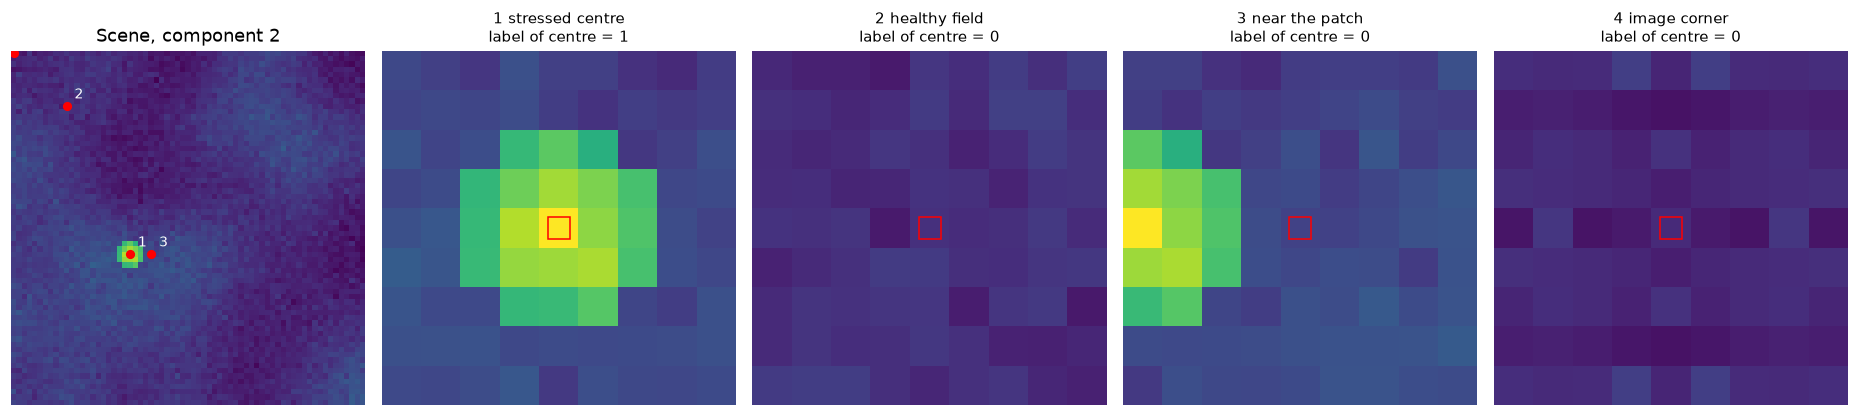

In [25]:
examples = [
    ("1 stressed centre", (38, 22)),
    ("2 healthy field", (10, 10)),
    ("3 near the patch", (38, 26)),
    ("4 image corner", (0, 0)),
]
comp = 1                                              # component 2 (index 1)
vmin, vmax = scores_n[:, :, comp].min(), scores_n[:, :, comp].max()

fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
axes[0].imshow(scores_n[:, :, comp], cmap="viridis", vmin=vmin, vmax=vmax)
for name, (rr, cc) in examples:
    axes[0].plot(cc, rr, "o", color="red", ms=5)
    axes[0].annotate(name[0], (cc + 1.5, rr - 1.5), color="white", fontsize=9)
axes[0].set_title("Scene, component 2")
axes[0].axis("off")

for ax, (name, (rr, cc)) in zip(axes[1:], examples):
    ax.imshow(windows[rr, cc][comp], cmap="viridis", vmin=vmin, vmax=vmax)
    ax.plot(R, R, "s", mfc="none", mec="red", ms=14)          # the centre pixel
    ax.set_title(f"{name}\nlabel of centre = {int(labels[rr, cc])}", fontsize=10)
    ax.axis("off")

fig.tight_layout()
save_fig(fig, "hybridsn_patches.png")
plt.show()

## 7. A `Dataset` that cuts patches on demand

Same idea as in notebook 05, but each sample is now a patch. `__getitem__` takes the window at one centre pixel and returns it with a **channel axis of size 1** in front: `(1, K, 9, 9)`. With the batch axis the model sees `(batch, 1, K, 9, 9)`, exactly what `Conv3d` expects.

Patches are cut **when requested**, from the view, so the full set of patches never sits in memory at once. The dataset takes a list of **centre pixels**, which is what lets us choose training and validation areas by location in Part B. `np.ascontiguousarray` copies just one small patch so that PyTorch gets a normal, writable array.

In [26]:
class PatchDataset(Dataset):
    def __init__(self, windows, centres, labels):
        self.windows = windows            # (H, W, K, P, P) view, no copy
        self.centres = centres            # (n, 2) array of (row, col)
        self.labels = labels              # (n,) 0 = healthy, 1 = stressed

    def __len__(self):
        return len(self.centres)

    def __getitem__(self, i):
        r, c = self.centres[i]
        patch = torch.from_numpy(np.ascontiguousarray(self.windows[r, c]))     # (K, P, P)
        return patch.unsqueeze(0), torch.tensor(float(self.labels[i]))         # (1, K, P, P), scalar


rows, cols = np.nonzero(valid)                        # every valid pixel is a centre
centres = np.stack([rows, cols], axis=1)
y_all = labels[rows, cols]

dataset = PatchDataset(windows, centres, y_all)
loader = DataLoader(dataset, batch_size=64, shuffle=True)

xb, yb = next(iter(loader))
print("dataset size:", len(dataset), "| batches per epoch:", len(loader))
print("one batch:", tuple(xb.shape), xb.dtype, "| labels:", tuple(yb.shape), yb.dtype)

dataset size: 4489 | batches per epoch: 71
one batch: (64, 1, 10, 9, 9) torch.float32 | labels: (64,) torch.float32


## 8. The model

The layout follows HybridSN, scaled down:

1. **Three 3D convolutions** (8, 16 and 32 filters, each 3 x 3 x 3) with ReLU. They look at bands and neighbouring pixels together. Bands shrink 10 -> 8 -> 6 -> 4, height and width 9 -> 7 -> 5 -> 3.
2. **Reshape**: the 32 channels and 4 remaining bands are merged into 128 ordinary channels, so a 2D convolution can take over.
3. **One 2D convolution** (64 filters, 3 x 3), which reduces the 3 x 3 map to a single position.
4. **Classifier**: two fully connected layers with **Dropout** (randomly switching off 40% of the units during training so the model cannot lean on any single one), then **one logit** for "stressed", as in notebook 05.

The original uses larger spectral kernels (7 and 5) because it has 30 bands. With only 10 components they would shrink the band axis to nothing, so we use 3 throughout.

Instead of working out the size of the first fully connected layer by hand, the model measures it by pushing a dummy patch through, so changing `PATCH` or `n_bands` never breaks it. `verbose=True` prints the shape after every stage.

In [27]:
class HybridSNMock(nn.Module):
    def __init__(self, n_bands=10, patch=9, dropout=0.4):
        super().__init__()
        self.spectral_spatial = nn.Sequential(                 # 3D part
            nn.Conv3d(1, 8, kernel_size=3), nn.ReLU(),
            nn.Conv3d(8, 16, kernel_size=3), nn.ReLU(),
            nn.Conv3d(16, 32, kernel_size=3), nn.ReLU(),
        )
        with torch.no_grad():                                  # measure the shape instead of computing it by hand
            d, h, w = self.spectral_spatial(torch.zeros(1, 1, n_bands, patch, patch)).shape[2:]

        self.spatial = nn.Sequential(                          # 2D part
            nn.Conv2d(32 * d, 64, kernel_size=3), nn.ReLU(),
        )
        with torch.no_grad():
            flat = self.spatial(torch.zeros(1, 32 * d, h, w)).numel()

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 1),                                  # ONE logit: "stressed"
        )

    def forward(self, x, verbose=False):
        show = (lambda name, t: print(f"{name:<28}{tuple(t.shape)}")) if verbose else (lambda name, t: None)
        show("input", x)
        x = self.spectral_spatial(x)                           # (N, 32, D', H', W')
        show("after 3 x Conv3d", x)
        n, c, d, h, w = x.shape
        x = x.reshape(n, c * d, h, w)                          # merge channels and bands
        show("reshaped for 2D", x)
        x = self.spatial(x)
        show("after Conv2d", x)
        x = self.classifier(x).squeeze(1)
        show("output (one logit each)", x)
        return x


model = HybridSNMock(n_bands=K, patch=PATCH)
print("shape after every stage, for 2 patches:")
_ = model(xb[:2], verbose=True)

print()
for name, block in model.named_children():
    print(f"{name:<18} parameters: {sum(p.numel() for p in block.parameters()):>7}")
print(f"{'total':<18} parameters: {sum(p.numel() for p in model.parameters()):>7}")

shape after every stage, for 2 patches:
input                       (2, 1, 10, 9, 9)
after 3 x Conv3d            (2, 32, 4, 3, 3)
reshaped for 2D             (2, 128, 3, 3)
after Conv2d                (2, 64, 1, 1)
output (one logit each)     (2,)

spectral_spatial   parameters:   17552
spatial            parameters:   73792
classifier         parameters:   16641
total              parameters:  107985


## 9. How fast is it on this computer?

A quick measurement of one training step (forward, backward and update) on a batch of 64 patches, so we know what an epoch costs on **your** CPU before the Part B training run. The first call is a warm-up and is not counted.

In [28]:
timing_model = HybridSNMock(n_bands=K, patch=PATCH)
timing_opt = torch.optim.Adam(timing_model.parameters(), lr=1e-3)
timing_loss = nn.BCEWithLogitsLoss()
xt, yt = xb[:64], yb[:64]


def one_step():
    timing_opt.zero_grad()
    timing_loss(timing_model(xt), yt).backward()
    timing_opt.step()


one_step()                                            # warm-up
times = []
for _ in range(10):
    start = time.perf_counter()
    one_step()
    times.append(time.perf_counter() - start)

ms = float(np.median(times)) * 1000
print("CPU threads used by PyTorch:", torch.get_num_threads())
print(f"one training step on 64 patches: {ms:.1f} ms")
print(f"estimated time for one epoch ({len(loader)} batches): {ms * len(loader) / 1000:.1f} s")

CPU threads used by PyTorch: 4
one training step on 64 patches: 16.6 ms
estimated time for one epoch (71 batches): 1.2 s


## 10. Two bug checks before real training

**Gradient check.** After one backward pass, **every** parameter must have received a non-zero gradient. If a layer's gradient is `None` or zero, something is cut off (a wrong reshape, a detached tensor).

**Overfit one small batch.** We take 16 stressed and 16 healthy patches and train on just those 32 repeatedly. A correct pipeline must drive the loss to nearly zero. This batch is deliberately balanced so a plain loss works. We set `dropout=0` here, since dropout adds noise that slows memorising. This is a **bug check, not an evaluation**: the model sees the same 32 patches it is scored on. In the mock cube stressed and healthy patches differ strongly, so expect the loss to collapse within a few dozen steps; what matters is that it falls and nothing is stuck.

In [29]:
rng = np.random.default_rng(0)
stressed_idx = rng.choice(np.where(y_all == 1)[0], 16, replace=False)
healthy_idx = rng.choice(np.where(y_all == 0)[0], 16, replace=False)
idx = np.concatenate([stressed_idx, healthy_idx])

bx = torch.stack([dataset[i][0] for i in idx])        # (32, 1, K, P, P)
by = torch.stack([dataset[i][1] for i in idx])        # (32,)

torch.manual_seed(0)
check_model = HybridSNMock(n_bands=K, patch=PATCH, dropout=0.0)
check_opt = torch.optim.Adam(check_model.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()

for step in range(151):
    check_opt.zero_grad()
    loss = loss_fn(check_model(bx), by)
    loss.backward()
    if step == 0:
        missing = [n for n, p in check_model.named_parameters() if p.grad is None or p.grad.abs().sum() == 0]
        print("parameters without gradient after the first backward:", missing if missing else "none (good)")
    check_opt.step()
    if step in (0, 5, 10, 25, 50, 100, 150):
        print(f"step {step:>3}  loss {loss.item():.2e}")

check_model.eval()
with torch.no_grad():
    acc = ((check_model(bx) > 0).float() == by).float().mean().item()
print()
print(f"accuracy on these 32 patches: {acc:.0%}  (a bug check only: it is the training data)")

parameters without gradient after the first backward: none (good)
step   0  loss 6.93e-01
step   5  loss 6.09e-01
step  10  loss 1.29e-01
step  25  loss 1.24e-16
step  50  loss 2.15e-30
step 100  loss 3.25e-32
step 150  loss 3.15e-32

accuracy on these 32 patches: 100%  (a bug check only: it is the training data)


## Takeaways (Part A)

- A **patch** gives the model the pixel's spectrum **and** its neighbourhood. Its label is the label of the **centre pixel**.
- `Conv3d` input is `(batch, channels, bands, H, W)`. Each size shrinks by `kernel - 1` without padding. Weights are shared along the spectrum, so 3D filters are economical.
- **Reflect padding** keeps edge pixels usable. `sliding_window_view` gives every patch as a **view**, so memory stays flat.
- The **Dataset takes a list of centre pixels**, which makes a spatial split easy.
- HybridSN idea: **3D convs -> reshape -> 2D conv -> classifier**. The reshape merges channels and bands into 2D channels.
- Before real training: check **shapes**, **gradients in every parameter**, and that the model can **overfit one small batch**.

## Part B. Train and evaluate on separate regions

### 11. Split the mock field

Notebook 02 simulates a single stressed spot only five rows across. Split at row 38, through that spot, so that both regions contain stressed centres. Cut the scene **before** extracting the 9 × 9 patches and reflect-pad each region at its own boundary. This keeps every source pixel on one side while retaining the rare examples. Boundary patches therefore see mirrored neighbours, and both regions sample the same simulated event.

In [30]:
split_row = 38
train_rows = slice(0, split_row)
val_rows = slice(split_row, H)

train_counts = np.bincount(labels[train_rows][valid[train_rows]], minlength=2)
val_counts = np.bincount(labels[val_rows][valid[val_rows]], minlength=2)
for name, (healthy, stressed) in (("Training", train_counts), ("Validation", val_counts)):
    assert healthy > 0 and stressed > 0, f"{name} requires both classes"
    print(f"{name}: {healthy} healthy and {stressed} stressed centres")
assert train_counts.sum() + val_counts.sum() == valid.sum()

Training: 2538 healthy and 8 stressed centres
Validation: 1930 healthy and 13 stressed centres


### 12. Fit the spectral preprocessing on training pixels

The PCA scores used for the Part A demonstrations were fitted on the whole cube. Start again from the reflectance cube from notebook 03 and reuse notebook 04’s fixed wavelength selection. Fit the band scaling and ten PCA components on valid training spectra. Whitening scales each component to unit sample variance using its training eigenvalue. Apply the fitted transform to both regions.

In [31]:
import h5py
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

with h5py.File(REPO_ROOT / "data/mock/mock_cube.h5", "r") as source:
    wavelengths = source["wavelengths_nm"][...]
    keep = np.isin(wavelengths, data["wavelengths_kept"])
    assert np.array_equal(wavelengths[keep], data["wavelengths_kept"])
    assert np.array_equal(source["labels"][...], labels)
    spectra = source["cube"][...][..., keep]

train_spectra = spectra[train_rows][valid[train_rows]].astype(np.float64)
band_scaler = StandardScaler().fit(train_spectra)
train_scaled = band_scaler.transform(train_spectra)
pca = PCA(n_components=K, whiten=True, svd_solver="full").fit(train_scaled)

def region_dataset(rows):
    region_valid = valid[rows]
    components = np.zeros((*region_valid.shape, K), dtype=np.float32)
    scaled = band_scaler.transform(spectra[rows][region_valid].astype(np.float64))
    components[region_valid] = pca.transform(scaled)
    padded_region = np.pad(components, ((R, R), (R, R), (0, 0)), mode="reflect")
    region_windows = np.lib.stride_tricks.sliding_window_view(
        padded_region, (PATCH, PATCH), axis=(0, 1)
    )
    return PatchDataset(region_windows, np.argwhere(region_valid), labels[rows][region_valid])

train_set = region_dataset(train_rows)
val_set = region_dataset(val_rows)
assert len(train_set) == train_counts.sum() and len(val_set) == val_counts.sum()
# The nearest rows visible at the split are reflected within their own regions.
train_source_rows = np.pad(np.arange(H)[train_rows], R, mode="reflect")
val_source_rows = np.pad(np.arange(H)[val_rows], R, mode="reflect")
assert np.intersect1d(train_source_rows, val_source_rows).size == 0
print(f"PCA fitted on {pca.n_samples_} pixels. Training and validation patches share zero source rows.")

PCA fitted on 2546 pixels. Training and validation patches share zero source rows.


### 13. Train the HybridSN classifier

Start with fresh weights and shuffle only the training patches. The positive weight in the binary cross-entropy loss is the number of healthy training centres divided by the number of stressed training centres. This gives both classes equal total weight over an epoch. Use a fixed 16 epochs and evaluate the final model at a fixed logit threshold of zero.

In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True,
                          generator=torch.Generator().manual_seed(0))
val_loader = DataLoader(val_set, batch_size=64)
trained_model = HybridSNMock(n_bands=K, patch=PATCH).to(device)
optimizer = torch.optim.Adam(trained_model.parameters(), lr=1e-3)
pos_weight = torch.tensor(train_counts[0] / train_counts[1], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print(f"Device {device} | stressed-class loss weight {pos_weight.item():.1f}")

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    logits, targets = [], []
    for patches, target in loader:
        output = model(patches.to(device))
        total_loss += criterion(output, target.to(device)).item() * len(target)
        logits.append(output.cpu())
        targets.append(target)
    return total_loss / len(loader.dataset), torch.cat(logits).numpy(), torch.cat(targets).numpy()

epochs = 16
train_losses, val_losses = [], []
for epoch in range(1, epochs + 1):
    trained_model.train()
    total_loss = 0.0
    for patches, target in train_loader:
        optimizer.zero_grad()
        logits = trained_model(patches.to(device))
        loss = criterion(logits, target.to(device))
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(target)
    train_losses.append(total_loss / len(train_set))
    val_loss, val_logits, val_targets = evaluate(trained_model, val_loader)
    val_losses.append(val_loss)
    if epoch == 1 or epoch % 4 == 0:
        print(f"Epoch {epoch:2d} | train loss {train_losses[-1]:.4f} | validation loss {val_loss:.4f}")

Device cpu | stressed-class loss weight 317.2
Epoch  1 | train loss 5.8341 | validation loss 6.2107
Epoch  4 | train loss 0.9214 | validation loss 1.2093
Epoch  8 | train loss 0.0555 | validation loss 0.0391
Epoch 12 | train loss 0.0273 | validation loss 0.0231
Epoch 16 | train loss 0.0231 | validation loss 0.1377


### 14. Evaluate stressed pixels on the held-out rows

Precision is the fraction of flagged centres that are stressed. Recall is the fraction of stressed centres found. F1 balances the two. The confusion counts show how much each of the 13 stressed validation pixels affects these metrics.

TP 13 | FP 59 | FN 0 | TN 1871
Stressed precision 0.181 | recall 1.000 | F1 0.306
Average precision 1.000 | validation prevalence 0.007


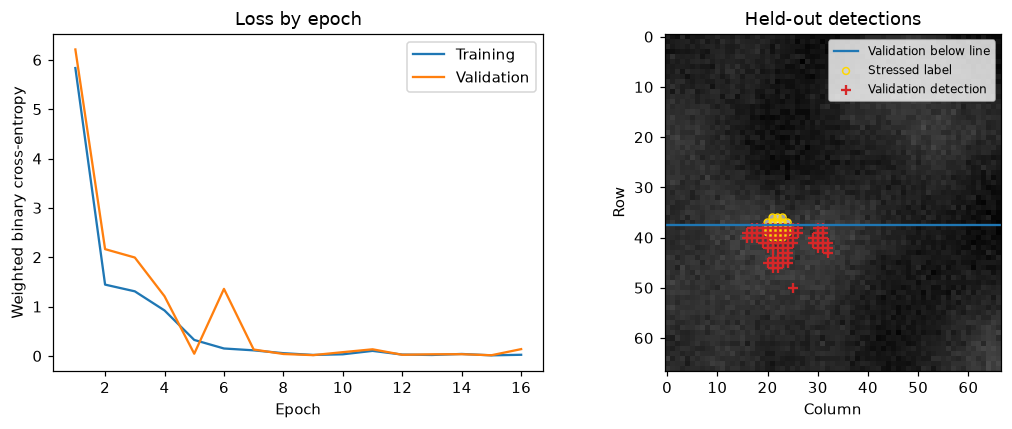

In [33]:
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_fscore_support

flagged = val_logits > 0
tn, fp, fn, tp = confusion_matrix(val_targets, flagged, labels=[0, 1]).ravel()
precision, recall, f1, _ = precision_recall_fscore_support(
    val_targets, flagged, average="binary", zero_division=0
)
print(f"TP {tp} | FP {fp} | FN {fn} | TN {tn}")
print(f"Stressed precision {precision:.3f} | recall {recall:.3f} | F1 {f1:.3f}")
print(f"Average precision {average_precision_score(val_targets, val_logits):.3f}"
      f" | validation prevalence {val_targets.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(range(1, epochs + 1), train_losses, label="Training")
axes[0].plot(range(1, epochs + 1), val_losses, label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Weighted binary cross-entropy", title="Loss by epoch")
axes[0].legend()
axes[1].imshow(scores_n[:, :, 1], cmap="gray")
axes[1].axhline(split_row - 0.5, color="tab:blue", label="Validation below line")
r, c = np.where((labels == 1) & valid)
axes[1].scatter(c, r, s=20, facecolors="none", edgecolors="gold", label="Stressed label")
r, c = val_set.centres[flagged].T
axes[1].scatter(c, r + split_row, marker="+", color="tab:red", label="Validation detection")
axes[1].set(xlabel="Column", ylabel="Row", title="Held-out detections")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Reading this run.** All 13 stressed validation pixels ranked above the healthy pixels, giving average precision of 1.000. At the fixed decision threshold the model also flagged 59 healthy pixels. Only 13 of 72 alerts were correct (18.1% precision), despite 100% recall. Both regions contain pieces of the same simulated spot, so these results describe detection within this field.

### 15. Keep the trained model

Save the model weights together with the wavelength selection, band scaling, PCA projection and whitening scale needed to prepare new patches. The labels in this exercise represent synthetic spectral stress. Evaluating chemical stress in crops requires spectra with verified treatment or exposure labels and independent fields or experiments.

In [34]:
model_dir = REPO_ROOT / "models"
model_dir.mkdir(exist_ok=True)
checkpoint_path = model_dir / "hybridsn_mock.pt"
checkpoint = {
    "state_dict": trained_model.cpu().state_dict(),
    "patch": PATCH, "n_bands": K, "threshold_logit": 0.0,
    "wavelengths_nm": torch.from_numpy(wavelengths[keep]),
    "band_mean": torch.from_numpy(band_scaler.mean_),
    "band_scale": torch.from_numpy(band_scaler.scale_),
    "pca_mean": torch.from_numpy(pca.mean_),
    "pca_components": torch.from_numpy(pca.components_),
    "pca_scale": torch.from_numpy(np.sqrt(pca.explained_variance_)),
}
torch.save(checkpoint, checkpoint_path)
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
restored = HybridSNMock(n_bands=saved["n_bands"], patch=saved["patch"])
restored.load_state_dict(saved["state_dict"])
restored.eval()
patches, _ = next(iter(val_loader))
with torch.no_grad():
    np.testing.assert_allclose(restored(patches).numpy(), val_logits[:len(patches)], rtol=1e-4, atol=1e-4)
print(f"Reloaded {checkpoint_path.name} and reproduced the first validation batch.")

Reloaded hybridsn_mock.pt and reproduced the first validation batch.
